# Final Project: HuffPost News Category Classification

**Team 23**
- Lucy Bing
- Lisamarie Bennett
- Ikechi Mbeyi

**Course:** DX703  Advanced Machine Learning & AI, Spring 2026
**Date:** April 2026
**Purpose:** This notebook presents a complete, reproducible implementation of a multi-class text classification pipeline for the HuffPost News Category Dataset, including data preparation, model training, and evaluation.

---

## A.1: Setup and Context

This section provides a summary of the work completed in Milestones 1 and 2, sets up the project environment, and implements the finalized preprocessing pipeline.

### Summary of Milestones 1 and 2

**Milestone 1 — Problem Framing and Data Exploration**

In Milestone 1, we selected the HuffPost News Category Dataset over Food-101 because text classification felt more relevant to the kinds of problems we expect to encounter outside of class and because NLP is an area we wanted more hands-on experience with. The dataset contains approximately 200,853 news articles, each with a headline, a short description, and one of 41 category labels.

Our EDA revealed several key characteristics that shaped our later decisions. The most important finding was the significant class imbalance: POLITICS dominates the dataset with over 32,000 samples, while categories like EDUCATION and CULTURE & ARTS have only about 1,000 each, giving an imbalance ratio of roughly 9.6x between the largest class and the median. We also found semantically overlapping category pairs such as PARENTS vs PARENTING, ARTS vs ARTS & CULTURE vs CULTURE & ARTS, and STYLE vs STYLE & BEAUTY that we expected would confuse the model. We checked text lengths using the DistilBERT tokenizer and found that 73 tokens covered most samples, while 128 preserved nearly all articles with minimal truncation. We also identified duplicate records, including repeated text entries and a small number of texts assigned to conflicting categories, which would need to be addressed during cleaning.

Based on these findings, we framed the task as multi-class classification using headline + short description as input, chose macro-averaged F1 as our primary metric to account for the class imbalance, and proposed using class weighting during training.

**Milestone 2 — Data Preparation and Model Exploration**

In Milestone 2, we built the full preprocessing pipeline and trained three progressively more complex models.

For data preparation, we combined each headline and short description with a [SEP] separator, removed empty rows, removed texts assigned to multiple categories, and deduplicated the dataset. We encoded the 41 category labels as integers, created stratified 80/10/10 train/validation/test splits with a fixed random seed of 42, built a TextVectorization layer adapted only on the training set, and computed balanced class weights using sklearn.

We then trained and compared three models:

1. **Baseline (Embedding + GlobalAveragePooling1D):** A simple embedding-based model that averages token representations into a single vector. It reached a test accuracy of 0.5271 and a macro F1 of 0.4492. The main limitation was that averaging word embeddings loses word order and phrase-level context.

2. **Custom CNN (Embedding + Conv1D + dual pooling):** We increased the embedding dimension to 96, added SpatialDropout1D, and used a Conv1D layer with both global max and average pooling to capture local phrase patterns. This improved modestly to a test accuracy of 0.5335 and macro F1 of 0.4623, but the gains were small because a single convolutional layer still has limited capacity for understanding language.

3. **DistilBERT (fine-tuned):** We fine-tuned DistilBERT with all layers trainable, using a learning rate of 2e-5, early stopping with patience of 2, and a batch size of 32. This reached a test accuracy of 0.7089 and macro F1 of 0.6043, a major improvement over both earlier models. Training took about 10.5 minutes compared to under 1 minute for the smaller models, but the performance gain was large enough to justify the computational cost.

The error analysis from Milestone 2 confirmed that most remaining mistakes come from semantically overlapping categories like HEALTHY LIVING vs WELLNESS, PARENTS vs PARENTING, and WORLD NEWS vs THE WORLDPOST. Based on these results, we selected DistilBERT as the final model to retrain in this notebook.

### A.1.1 — Environment Setup and Imports

In [1]:
# ============================================
# Useful Imports
# ============================================

# --- Standard Libraries
import os
import random
import re
import time
import math
from collections import Counter

# --- Core Data / Numerics
import numpy as np
import pandas as pd

# --- Visualization
import matplotlib.pyplot as plt

# --- TensorFlow / Keras
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras import layers, models, callbacks
import keras
import keras_hub

# --- Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.metrics import confusion_matrix

# --- Reproducibility
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.19.0
Keras version: 3.13.2
GPU available: True


In [2]:
# If needed (in a new env):
# !pip install -q keras-hub datasets

### A.1.2 — Load the Dataset

In [3]:
# --- Hugging Face Datasets
from datasets import load_dataset

# JSON mirror that preserves fields: headline, short_description, category, authors, link, date
URL = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"

huff_all = load_dataset("json", data_files=URL, split="train")

print(huff_all)
print("Columns:", huff_all.column_names)
print("Total rows:", len(huff_all))

# show a few sample rows
sample_df = pd.DataFrame(huff_all[:3])
display(sample_df[["category", "headline", "short_description"]])

News_Category_Dataset_v2.json:   0%|          | 0.00/83.9M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['category', 'headline', 'authors', 'link', 'short_description', 'date'],
    num_rows: 200853
})
Columns: ['category', 'headline', 'authors', 'link', 'short_description', 'date']
Total rows: 200853


,category,headline,short_description
0,CRIME,There Were 2 Mass Shootings In Texas Last Week...,She left her husband. He killed their children...
1,ENTERTAINMENT,Will Smith Joins Diplo And Nicky Jam For The 2...,Of course it has a song.
2,ENTERTAINMENT,Hugh Grant Marries For The First Time At Age 57,The actor and his longtime girlfriend Anna Ebe...


In [4]:
# convert to pandas and keep only the columns needed
df = huff_all.to_pandas()[["headline", "short_description", "category"]].copy()

print("Initial shape:", df.shape)
display(df.head())

Initial shape: (200853, 3)


,headline,short_description,category
0,There Were 2 Mass Shootings In Texas Last Week...,She left her husband. He killed their children...,CRIME
1,Will Smith Joins Diplo And Nicky Jam For The 2...,Of course it has a song.,ENTERTAINMENT
2,Hugh Grant Marries For The First Time At Age 57,The actor and his longtime girlfriend Anna Ebe...,ENTERTAINMENT
3,Jim Carrey Blasts 'Castrato' Adam Schiff And D...,The actor gives Dems an ass-kicking for not fi...,ENTERTAINMENT
4,Julianna Margulies Uses Donald Trump Poop Bags...,"The ""Dietland"" actress said using the bags is ...",ENTERTAINMENT


### A.1.3 — Exploratory Data Analysis

In [5]:
# number of unique classes
unique_categories = sorted(df["category"].unique())
print("Number of unique categories:", len(unique_categories))
print("\nCategories:", unique_categories)

Number of unique categories: 41

Categories: ['ARTS', 'ARTS & CULTURE', 'BLACK VOICES', 'BUSINESS', 'COLLEGE', 'COMEDY', 'CRIME', 'CULTURE & ARTS', 'DIVORCE', 'EDUCATION', 'ENTERTAINMENT', 'ENVIRONMENT', 'FIFTY', 'FOOD & DRINK', 'GOOD NEWS', 'GREEN', 'HEALTHY LIVING', 'HOME & LIVING', 'IMPACT', 'LATINO VOICES', 'MEDIA', 'MONEY', 'PARENTING', 'PARENTS', 'POLITICS', 'QUEER VOICES', 'RELIGION', 'SCIENCE', 'SPORTS', 'STYLE', 'STYLE & BEAUTY', 'TASTE', 'TECH', 'THE WORLDPOST', 'TRAVEL', 'WEDDINGS', 'WEIRD NEWS', 'WELLNESS', 'WOMEN', 'WORLD NEWS', 'WORLDPOST']


In [6]:
# label frequency counts
label_freq = df["category"].value_counts().sort_values(ascending=False)

print("Top 10 most common categories:")
print(label_freq.head(10))

print("\nBottom 5 least common categories:")
print(label_freq.tail(5))

# imbalance summary
max_count = int(label_freq.max())
median_count = int(label_freq.median())
min_count = int(label_freq.min())
imbalance_ratio = max_count / median_count
print(f"\nImbalance ratio (max / median): {imbalance_ratio:.2f}")
print(f"Largest class: {label_freq.idxmax()} ({max_count})")
print(f"Smallest class: {label_freq.idxmin()} ({min_count})")

Top 10 most common categories:
category
POLITICS          32739
WELLNESS          17827
ENTERTAINMENT     16058
TRAVEL             9887
STYLE & BEAUTY     9649
PARENTING          8677
HEALTHY LIVING     6694
QUEER VOICES       6314
FOOD & DRINK       6226
BUSINESS           5937
Name: count, dtype: int64

Bottom 5 least common categories:
category
ENVIRONMENT       1323
COLLEGE           1144
LATINO VOICES     1129
CULTURE & ARTS    1030
EDUCATION         1004
Name: count, dtype: int64

Imbalance ratio (max / median): 9.61
Largest class: POLITICS (32739)
Smallest class: EDUCATION (1004)


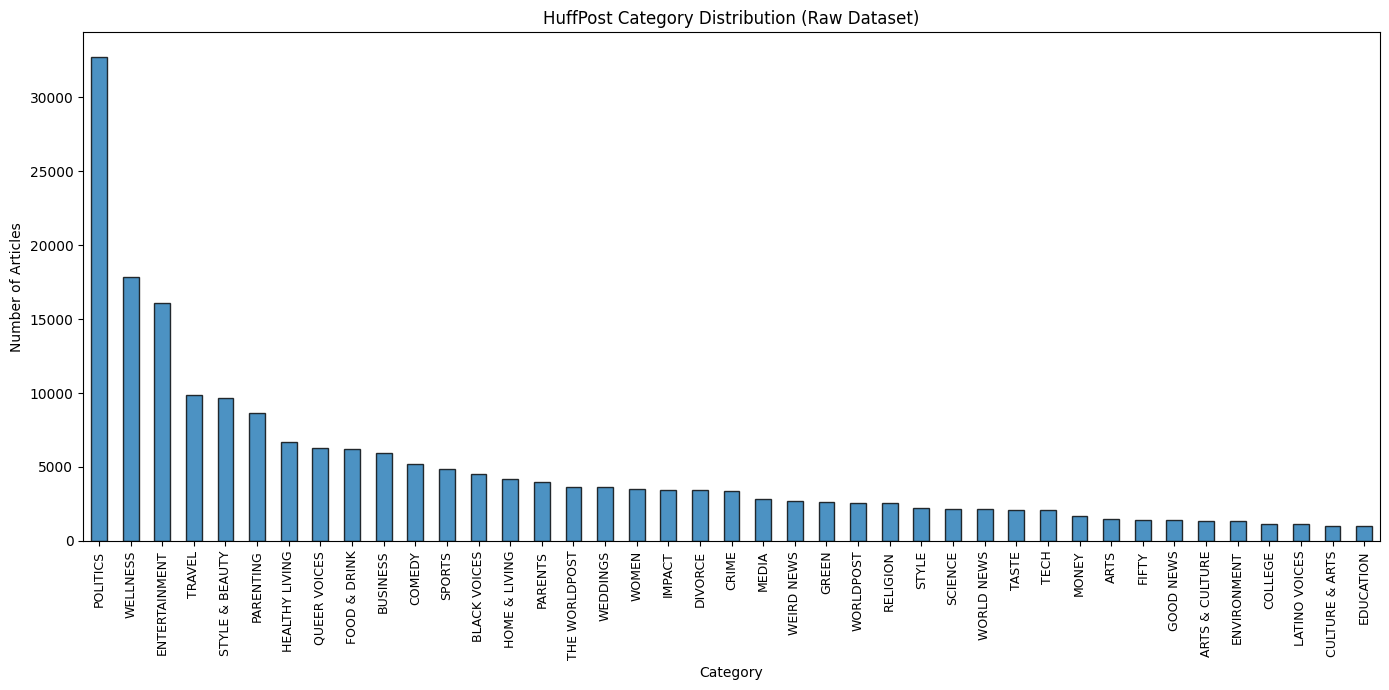

In [7]:
# plot class imbalance

plt.figure(figsize=(14, 7))
label_freq.plot(kind="bar", edgecolor="black", alpha=0.8)
plt.title("HuffPost Category Distribution (Raw Dataset)")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=90, fontsize=9)
plt.tight_layout()
plt.show()

In [8]:
# check for empty headline or short_description

empty_headline = df["headline"].fillna("").str.strip().eq("").sum()
empty_summary = df["short_description"].fillna("").str.strip().eq("").sum()

print("Empty headlines:", empty_headline)
print("Empty short descriptions:", empty_summary)

# check duplicates
print("\nExact duplicate rows:", df.duplicated().sum())

Empty headlines: 6
Empty short descriptions: 19712

Exact duplicate rows: 470


In [9]:
print("\nExact duplicate rows in 3-column dataframe:", df.duplicated().sum())


Exact duplicate rows in 3-column dataframe: 470


In [10]:
# check for same combined text assigned to multiple categories
df["combined_text"] = (
    df["headline"].fillna("").str.strip() + " [SEP] " +
    df["short_description"].fillna("").str.strip()
)


conflict_counts = (
    df.groupby("combined_text")["category"]
      .nunique()
)

num_conflicting_texts = (conflict_counts > 1).sum()

print("Texts assigned to more than one category:", num_conflicting_texts)

Texts assigned to more than one category: 15


In [11]:
conflicting_examples = conflict_counts[conflict_counts > 1].head(10)
print(conflicting_examples)

combined_text
 [SEP]                                                                                                                                                                                                                                                                                                                                          5
A Conversation With Decorator and Fashion Designer Kelly Wearstler [SEP] Much like the arresting color combinations she washes her rooms with, she applies the same fearless approach to color in her fashion collections. Below the decorator slash designer talks about happiness, style and ball gowns as office attire.                     2
Bring Back Our Girls [SEP]                                                                                                                                                                                                                                                                                            

In [12]:
# text length statistics
df["headline_word_count"] = df["headline"].fillna("").str.split().str.len()
df["summary_word_count"] = df["short_description"].fillna("").str.split().str.len()

print("Headline word count summary:")
print(df["headline_word_count"].describe().round(1))

print("\nShort description word count summary:")
print(df["summary_word_count"].describe().round(1))

Headline word count summary:
count    200853.0
mean          9.5
std           3.1
min           0.0
25%           7.0
50%          10.0
75%          12.0
max          44.0
Name: headline_word_count, dtype: float64

Short description word count summary:
count    200853.0
mean         19.7
std          14.4
min           0.0
25%          10.0
50%          19.0
75%          24.0
max         243.0
Name: summary_word_count, dtype: float64


### A.1.4 — Final Preprocessing Pipeline

Our preprocessing pipeline follows the approach we established in Milestone 2, with the same cleaning steps, splitting strategy, and vectorization. The key steps are:

1. **Text combination** — concatenate headline and short description with a [SEP] separator
2. **Cleaning** — fill missing values, strip whitespace, normalize for deduplication
3. **Deduplication** — remove exact text duplicates and texts assigned to conflicting categories
4. **Label encoding** — map the 41 category strings to integer IDs
5. **Stratified splitting** — create 80/10/10 train/val/test splits preserving class proportions
6. **Vectorization** — convert text to padded integer sequences and prepare raw text arrays for DistilBERT
7. **Class weighting** — compute balanced class weights to address imbalance during training

In [13]:
# Fill missing values and strip whitespace
for col in ["headline", "short_description", "category"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

def combine_text(headline, summary):
    """Combine headline and short description with [SEP] separator."""
    if headline and summary:
        return f"{headline} [SEP] {summary}"
    elif headline:
        return headline
    elif summary:
        return summary
    else:
        return ""

# Keep a raw combined version for reference / future transformer work
df["text_raw"] = df.apply(
    lambda row: combine_text(row["headline"], row["short_description"]),
    axis=1
)

# Create a normalized version for cleaning / dedup checks
df["text_clean"] = (
    df["text_raw"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.lower()
)

print("After text construction:")
display(df[["category", "text_raw", "text_clean"]].head())

After text construction:


,category,text_raw,text_clean
0,CRIME,There Were 2 Mass Shootings In Texas Last Week...,there were 2 mass shootings in texas last week...
1,ENTERTAINMENT,Will Smith Joins Diplo And Nicky Jam For The 2...,will smith joins diplo and nicky jam for the 2...
2,ENTERTAINMENT,Hugh Grant Marries For The First Time At Age 5...,hugh grant marries for the first time at age 5...
3,ENTERTAINMENT,Jim Carrey Blasts 'Castrato' Adam Schiff And D...,jim carrey blasts 'castrato' adam schiff and d...
4,ENTERTAINMENT,Julianna Margulies Uses Donald Trump Poop Bags...,julianna margulies uses donald trump poop bags...


In [14]:
# check missing text and remove empty samples

empty_headline = (df["headline"] == "").sum()
empty_summary = (df["short_description"] == "").sum()
empty_text = (df["text_clean"] == "").sum()

print("Empty headlines:", empty_headline)
print("Empty short descriptions:", empty_summary)
print("Completely empty combined texts:", empty_text)

Empty headlines: 6
Empty short descriptions: 19712
Completely empty combined texts: 5


In [15]:
# Remove rows with no usable text
df = df[df["text_clean"] != ""].copy()

print("Shape after removing empty combined texts:", df.shape)

Shape after removing empty combined texts: (200848, 8)


In [16]:
# remove noisy duplicates and conflicting labels

# Exact duplicates based on normalized text
duplicate_text_count = df["text_clean"].duplicated().sum()
print("Duplicate normalized texts before removal:", duplicate_text_count)

Duplicate normalized texts before removal: 492


In [17]:
# Find texts that appear in more than one category
conflict_counts = df.groupby("text_clean")["category"].nunique()
conflicting_texts = conflict_counts[conflict_counts > 1].index

print("Number of text groups assigned to multiple categories:", len(conflicting_texts))

Number of text groups assigned to multiple categories: 15


In [18]:
# Remove conflicting rows entirely
df = df[~df["text_clean"].isin(conflicting_texts)].copy()

In [19]:
# Remove duplicate rows, keeping the first occurrence
df = df.drop_duplicates(subset="text_clean").copy()

print("Shape after removing conflicting texts and duplicates:", df.shape)

Shape after removing conflicting texts and duplicates: (200341, 8)


In [20]:
# encode labels
label_encoder = LabelEncoder()
df["label_id"] = label_encoder.fit_transform(df["category"])

num_classes = df["label_id"].nunique()

print("Number of classes:", num_classes)
print("\nSample label mapping:")
for i, class_name in enumerate(label_encoder.classes_[:10]):
    print(f"  {class_name} -> {i}")

Number of classes: 41

Sample label mapping:
  ARTS -> 0
  ARTS & CULTURE -> 1
  BLACK VOICES -> 2
  BUSINESS -> 3
  COLLEGE -> 4
  COMEDY -> 5
  CRIME -> 6
  CULTURE & ARTS -> 7
  DIVORCE -> 8
  EDUCATION -> 9


Top 10 largest classes:
category
POLITICS          32719
WELLNESS          17821
ENTERTAINMENT     16054
TRAVEL             9883
STYLE & BEAUTY     9508
PARENTING          8649
HEALTHY LIVING     6689
QUEER VOICES       6310
FOOD & DRINK       6225
BUSINESS           5933
Name: count, dtype: int64

Top 5 smallest classes:
category
ENVIRONMENT       1322
COLLEGE           1144
LATINO VOICES     1129
CULTURE & ARTS    1029
EDUCATION         1004
Name: count, dtype: int64

Largest class size: 32719
Median class size: 3401
Smallest class size: 1004

Imbalance ratio (max / median): 9.62


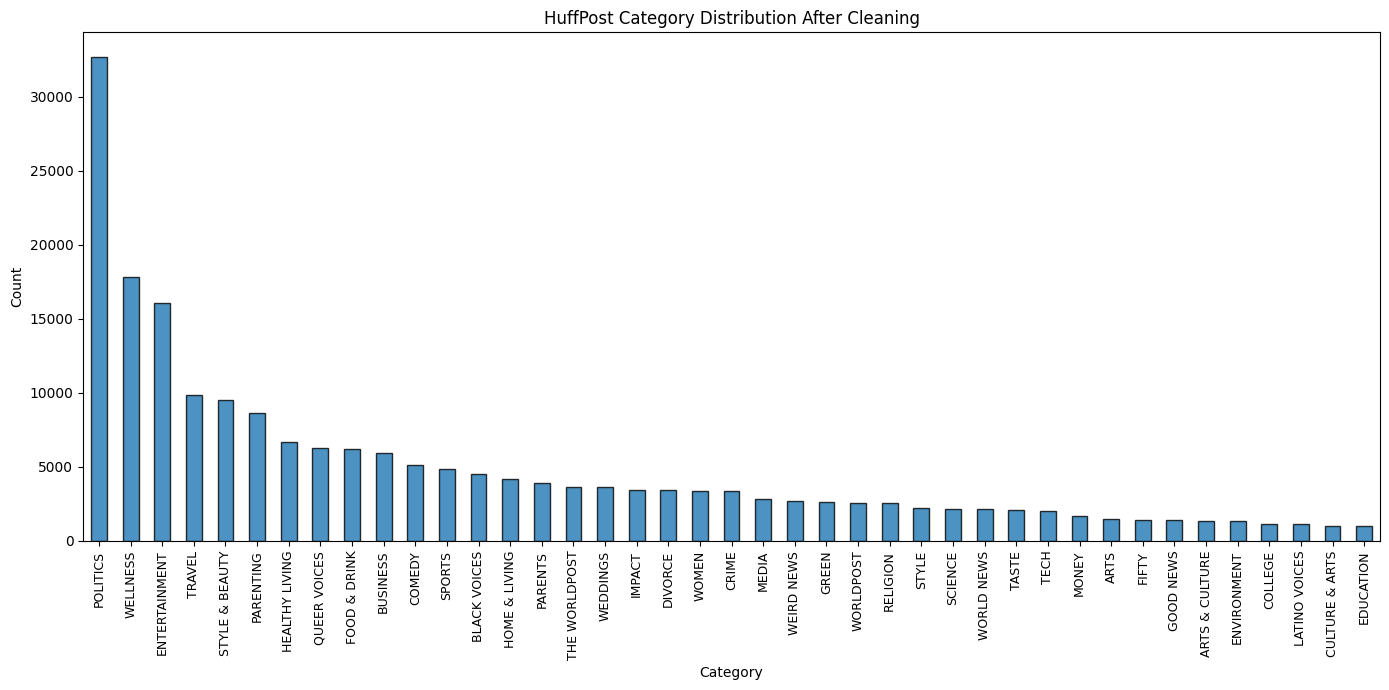

In [21]:
# post-cleaning class distribution

label_counts = df["category"].value_counts().sort_values(ascending=False)

max_count = int(label_counts.max())
median_count = int(label_counts.median())
min_count = int(label_counts.min())

print("Top 10 largest classes:")
print(label_counts.head(10))

print("\nTop 5 smallest classes:")
print(label_counts.tail(5))

print("\nLargest class size:", max_count)
print("Median class size:", median_count)
print("Smallest class size:", min_count)

imbalance_ratio = max_count / median_count
print(f"\nImbalance ratio (max / median): {imbalance_ratio:.2f}")

plt.figure(figsize=(14, 7))
label_counts.plot(kind="bar", edgecolor="black", alpha=0.8)
plt.title("HuffPost Category Distribution After Cleaning")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90, fontsize=9)
plt.tight_layout()
plt.show()

In [22]:
# use the Milestone 1 length choice for max length

MAX_LEN = 73        # from Milestone 1 length analysis
VOCAB_SIZE = 20000  # reasonable baseline vocabulary size

print("MAX_LEN:", MAX_LEN)
print("VOCAB_SIZE:", VOCAB_SIZE)

MAX_LEN: 73
VOCAB_SIZE: 20000


In [23]:
# create reproducible stratified splits

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=df["label_id"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temp_df["label_id"]
)

In [24]:
print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain ratio:", round(len(train_df) / len(df), 4))
print("Val ratio:", round(len(val_df) / len(df), 4))
print("Test ratio:", round(len(test_df) / len(df), 4))

Train shape: (160272, 9)
Validation shape: (20034, 9)
Test shape: (20035, 9)

Train ratio: 0.8
Val ratio: 0.1
Test ratio: 0.1


In [25]:
# leakage checks

train_texts = set(train_df["text_clean"])
val_texts = set(val_df["text_clean"])
test_texts = set(test_df["text_clean"])

train_val_overlap = len(train_texts & val_texts)
train_test_overlap = len(train_texts & test_texts)
val_test_overlap = len(val_texts & test_texts)

print("Train/Val overlap:", train_val_overlap)
print("Train/Test overlap:", train_test_overlap)
print("Val/Test overlap:", val_test_overlap)

Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0


In [26]:
# build the TextVectorization layer

vectorizer = TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_LEN,
    standardize="lower_and_strip_punctuation"
)

In [27]:
# Adapt only on the training text to avoid leakage
vectorizer.adapt(train_df["text_raw"].values)

print("Vectorizer vocabulary size:", len(vectorizer.get_vocabulary()))
print("First 20 vocabulary items:")
print(vectorizer.get_vocabulary()[:20])

Vectorizer vocabulary size: 20000
First 20 vocabulary items:
['', '[UNK]', np.str_('the'), np.str_('sep'), np.str_('to'), np.str_('a'), np.str_('of'), np.str_('and'), np.str_('in'), np.str_('is'), np.str_('for'), np.str_('that'), np.str_('on'), np.str_('you'), np.str_('with'), np.str_('i'), np.str_('it'), np.str_('are'), np.str_('this'), np.str_('be')]


In [28]:
# vectorize inputs and prepare labels

X_train = vectorizer(tf.constant(train_df["text_raw"].values))
X_val = vectorizer(tf.constant(val_df["text_raw"].values))
X_test = vectorizer(tf.constant(test_df["text_raw"].values))

y_train = train_df["label_id"].values
y_val = val_df["label_id"].values
y_test = test_df["label_id"].values

In [29]:
# One-hot labels for categorical_crossentropy
y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes=num_classes)
y_val_cat = tf.keras.utils.to_categorical(y_val, num_classes=num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes=num_classes)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

print("y_train_cat shape:", y_train_cat.shape)
print("y_val_cat shape:", y_val_cat.shape)
print("y_test_cat shape:", y_test_cat.shape)

X_train shape: (160272, 73)
X_val shape: (20034, 73)
X_test shape: (20035, 73)
y_train_cat shape: (160272, 41)
y_val_cat shape: (20034, 41)
y_test_cat shape: (20035, 41)


In [30]:
# Prepare the raw text inputs for DistilBERT
X_train_text = train_df["text_raw"].astype(str).values
X_val_text = val_df["text_raw"].astype(str).values
X_test_text = test_df["text_raw"].astype(str).values

print("Train text shape:", X_train_text.shape)
print("Validation text shape:", X_val_text.shape)
print("Test text shape:", X_test_text.shape)

Train text shape: (160272,)
Validation text shape: (20034,)
Test text shape: (20035,)


In [31]:
# compute class weights from the training split

classes = np.unique(y_train)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {int(cls): float(weight) for cls, weight in zip(classes, class_weights_array)}

print("Sample class weights:")
for k in list(class_weights.keys())[:10]:
    print(f"Class {k}: {class_weights[k]:.4f}")

Sample class weights:
Class 0: 3.2387
Class 1: 3.6499
Class 2: 1.0805
Class 3: 0.8237
Class 4: 4.2722
Class 5: 0.9465
Class 6: 1.4366
Class 7: 4.7498
Class 8: 1.4277
Class 9: 4.8681


In [32]:
# show representative processed examples

# pick one example with both headline and summary
both_example = train_df[
    (train_df["headline"].str.strip() != "") &
    (train_df["short_description"].str.strip() != "")
].iloc[0]

In [33]:
# pick one example with headline only
headline_only_example = train_df[
    (train_df["headline"].str.strip() != "") &
    (train_df["short_description"].str.strip() == "")
].iloc[0]

In [34]:
# pick one more general example from a different row
general_example = train_df.iloc[100]

example_rows = [both_example, headline_only_example, general_example]

for i, row in enumerate(example_rows, start=1):
    vectorized = vectorizer(tf.constant([row["text_raw"]])).numpy()[0]

    print("=" * 90)
    print(f"Example {i}")
    print(f"Category: {row['category']}")
    print(f"Label id: {row['label_id']}")
    print("\nHeadline:")
    print(row["headline"])
    print("\nShort description:")
    print(row["short_description"] if row["short_description"] else "[EMPTY]")
    print("\nCombined text:")
    print(row["text_raw"])
    print("\nCleaned text:")
    print(row["text_clean"])
    print("\nVectorized tokens (first 30):")
    print(vectorized[:30])
    print()

Example 1
Category: BLACK VOICES
Label id: 2

Headline:
Paula Patton, Condola Rashad, Tonya Lewis Lee And More: Week's Best Style Moments (PHOTOS)

Short description:
Paula Patton's outfit has love written all over it, so it's not wonder we adore the look so much. The "Baggage Claim" actress

Combined text:
Paula Patton, Condola Rashad, Tonya Lewis Lee And More: Week's Best Style Moments (PHOTOS) [SEP] Paula Patton's outfit has love written all over it, so it's not wonder we adore the look so much. The "Baggage Claim" actress

Cleaned text:
paula patton, condola rashad, tonya lewis lee and more: week's best style moments (photos) [sep] paula patton's outfit has love written all over it, so it's not wonder we adore the look so much. the "baggage claim" actress

Vectorized tokens (first 30):
[ 6680  7831     1     1 16379  4052  2041     7    35   417    87   201
   679    62     3  6680     1  2425    40    96  1666    43    76    16
    64    32    26  1057    21  9063]

Example 2
Cate

In [35]:
# final summary

max_count = int(label_counts.max())
median_count = int(label_counts.median())
min_count = int(label_counts.min())
imbalance_ratio = max_count / median_count

print("FINAL A.1 PREPROCESSING SUMMARY")
print("-" * 50)
print("Total cleaned samples:", len(df))
print("Number of classes:", num_classes)
print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))
print("Chosen max length:", MAX_LEN)
print("Vocabulary size cap:", VOCAB_SIZE)
print("Train/Val overlap:", train_val_overlap)
print("Train/Test overlap:", train_test_overlap)
print("Val/Test overlap:", val_test_overlap)
print("Number of class weights:", len(class_weights))
print("Largest class size:", max_count)
print("Median class size:", median_count)
print("Smallest class size:", min_count)
print(f"Imbalance ratio (max / median): {imbalance_ratio:.2f}")

FINAL A.1 PREPROCESSING SUMMARY
--------------------------------------------------
Total cleaned samples: 200341
Number of classes: 41
Train size: 160272
Validation size: 20034
Test size: 20035
Chosen max length: 73
Vocabulary size cap: 20000
Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0
Number of class weights: 41
Largest class size: 32719
Median class size: 3401
Smallest class size: 1004
Imbalance ratio (max / median): 9.62


---
## A.2: Model Selection and Retraining

### A.2.1 - Final Architecture and Model Selection

Based on the validation results from Milestone 2, we selected pretrained DistilBERT as the final model for this project. In Milestone 2, we compared three approaches: a simple baseline text model, a custom neural network trained from scratch, and a pretrained transformer model. DistilBERT gave the strongest validation performance overall, so it was the clearest model to carry forward into the final retraining stage. It also performed best in the earlier held out comparison, especially on the measures that mattered most for this dataset.

We made the final model choice by looking mainly at validation loss, validation accuracy, and macro F1. Those measures mattered because the HuffPost dataset contains 41 imbalanced classes, which means accuracy by itself does not fully show how well the model performs across categories. Macro F1 was especially useful because it gave a better sense of whether performance remained reasonably balanced across both common and less frequent labels. Overall, DistilBERT gave the best mix of strong validation accuracy and better class level performance, which made it the strongest final choice.

Architecturally, this model is a pretrained transformer encoder fine tuned for multiclass text classification. We used the distil_bert_base_en_uncased preset and adapted it for our 41 HuffPost categories. This architecture is a good fit for short news text because it captures context and word relationships much better than the models we trained from scratch, which helped it handle overlapping and nuanced categories more effectively.

In [36]:
# Final hyperparameter definitions

DISTILBERT_PRESET="distil_bert_base_en_uncased"
DISTILBERT_SEQ_LEN=128

FINAL_BATCH_SIZE=32
FINAL_EPOCHS=3
FINAL_LEARNING_RATE=2e-5

# In this final DistilBERT run, we did not add a custom LR scheduler,
# custom dropout layer, or explicit weight decay / L2 regularization.
FINAL_LR_SCHEDULER="None"
FINAL_DROPOUT="Preset architecture defaults only"
FINAL_WEIGHT_DECAY="None"
FINAL_FINE_TUNING_STRATEGY="Full fine-tuning"

In [37]:
# summarize the final training configuration for reproducibility

a2_hyperparams = pd.DataFrame({
    "Setting": [
        "Model preset",
        "Architecture type",
        "Sequence length",
        "Batch size",
        "Max epochs",
        "Learning rate",
        "Optimizer",
        "Loss",
        "Metric",
        "LR scheduler",
        "Additional dropout",
        "Weight decay / L2",
        "Fine-tuning strategy",
        "Validation split source",
        "Test set usage"
    ],
    "Value": [
        DISTILBERT_PRESET,
        "Pretrained transformer encoder (DistilBERT)",
        DISTILBERT_SEQ_LEN,
        FINAL_BATCH_SIZE,
        FINAL_EPOCHS,
        FINAL_LEARNING_RATE,
        "Adam",
        "SparseCategoricalCrossentropy(from_logits=True)",
        "accuracy",
        FINAL_LR_SCHEDULER,
        FINAL_DROPOUT,
        FINAL_WEIGHT_DECAY,
        FINAL_FINE_TUNING_STRATEGY,
        "Held-out validation split created in A.1",
        "Reserved for final evaluation in A.3"
    ]
})

display(a2_hyperparams)

,Setting,Value
0,Model preset,distil_bert_base_en_uncased
1,Architecture type,Pretrained transformer encoder (DistilBERT)
2,Sequence length,128
3,Batch size,32
4,Max epochs,3
5,Learning rate,0.00002
6,Optimizer,Adam
7,Loss,SparseCategoricalCrossentropy(from_logits=True)
8,Metric,accuracy
9,LR scheduler,None


### A.2.2 - Optimization Strategy and Callbacks

We used **Adam** with a small learning rate of **2e-5**, which is a standard and stable choice for fine-tuning transformer models. Because DistilBERT begins with pretrained language representations, a small learning rate is appropriate: it allows the model to adapt to the HuffPost classification task without changing the pretrained weights too aggressively.

For callbacks, we used **EarlyStopping** with `monitor="val_loss"`, `patience=2`, and `restore_best_weights=True`. This gave the model a chance to continue improving while still protecting against unnecessary overtraining. In Milestone 2, the best validation checkpoint occurred at **epoch 2**, so we keep the same callback logic here for a clean retraining of the selected final model.

The training procedure below retrains the final model from scratch using the **full training split**, a **held-out validation split**, and a **separate untouched test split** reserved for the evaluation section.

In [38]:
# Build the DistilBERT preprocessor and classifier

final_preprocessor = keras_hub.models.DistilBertTextClassifierPreprocessor.from_preset(
    DISTILBERT_PRESET,
    sequence_length=DISTILBERT_SEQ_LEN
)

final_model = keras_hub.models.DistilBertTextClassifier.from_preset(
    DISTILBERT_PRESET,
    num_classes=num_classes,
    preprocessor=final_preprocessor
)

final_model.summary()

Preprocessor: "distil_bert_text_classifier_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ distil_bert_tokenizer (DistilBertTokenizer)                   │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "distil_bert_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │      66,362,880 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 41)                │          31,529 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 66,985,001 (255.53 MB)

 Trainable params: 66,985,001 (255.53 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# compile the final model using the Milestone 2 fine-tuning setup

final_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=FINAL_LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

In [40]:
# define callbacks used during retraining

final_early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

final_callbacks = [final_early_stopping]

print("Callbacks configured:")
for cb in final_callbacks:
    print("-", cb.__class__.__name__)

Callbacks configured:
- EarlyStopping


### A.2.3 - Retraining the Final Model

The following training run cleanly retrains the selected final model using the same train/validation split strategy established in A.1. The test set is intentionally not used during training and will remain untouched until A.3. This keeps the final evaluation honest and consistent with the workflow established in Milestone 2.

In [41]:
# Retrain the final model from scratch

start_time = time.time()

final_history = final_model.fit(
    X_train_text,
    y_train,
    validation_data=(X_val_text, y_val),
    epochs=FINAL_EPOCHS,
    batch_size=FINAL_BATCH_SIZE,
    callbacks=final_callbacks,
    class_weight=class_weights,
    verbose=1
)
final_training_time_sec = time.time() - start_time
final_training_time_min = final_training_time_sec / 60

print(f"\nTraining time: {final_training_time_sec:.2f} seconds")
print(f"Training time: {final_training_time_min:.2f} minutes")
print("Epochs completed:", len(final_history.history["loss"]))

Epoch 1/3
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 302s 48ms/step - accuracy: 0.5415 - loss: 1.6890 - val_accuracy: 0.6284 - val_loss: 1.2795
Epoch 2/3
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 183s 36ms/step - accuracy: 0.6454 - loss: 1.0898 - val_accuracy: 0.6524 - val_loss: 1.1770
Epoch 3/3
5009/5009 ━━━━━━━━━━━━━━━━━━━━ 183s 37ms/step - accuracy: 0.6982 - loss: 0.8433 - val_accuracy: 0.6539 - val_loss: 1.2042

Training time: 668.91 seconds
Training time: 11.15 minutes
Epochs completed: 3


In [42]:
# Summarize the retraining run

best_epoch_idx = int(np.argmin(final_history.history["val_loss"]))
best_epoch_number = best_epoch_idx + 1

a2_training_summary = {
    "Best epoch": best_epoch_number,
    "Best validation loss": float(final_history.history["val_loss"][best_epoch_idx]),
    "Validation accuracy at best epoch": float(final_history.history["val_accuracy"][best_epoch_idx]),
    "Last training epoch train loss": float(final_history.history["loss"][-1]),
    "Last training epoch validation loss": float(final_history.history["val_loss"][-1]),
    "Last training epoch train accuracy": float(final_history.history["accuracy"][-1]),
    "Last training epoch validation accuracy": float(final_history.history["val_accuracy"][-1]),
    "Epochs trained": len(final_history.history["loss"]),
    "Training time (minutes)": float(final_training_time_min),
    "Total parameters": int(final_model.count_params())
}
for key, value in a2_training_summary.items():
    print(f"{key}: {value}")

Best epoch: 2
Best validation loss: 1.1770132780075073
Validation accuracy at best epoch: 0.6523909568786621
Last training epoch train loss: 0.8432567715644836
Last training epoch validation loss: 1.2041877508163452
Last training epoch train accuracy: 0.6981818675994873
Last training epoch validation accuracy: 0.6539382934570312
Epochs trained: 3
Training time (minutes): 11.14849325021108
Total parameters: 66985001


### A.2.4 Summary

This section takes the final model chosen in Milestone 2 and retrains it in a cleaner, more organized way. The model is still a pretrained DistilBERT text classifier fine tuned on the HuffPost dataset, using the same main settings as before: sequence length 128, learning rate 2e-5, batch size 32, and up to 3 epochs with early stopping based on validation loss. In this final retraining run, we also included balanced class weights from the training split so the model would put more attention on the smaller categories in this imbalanced 41 class problem.

The validation split remains separate during training, and the test split is still held back for final evaluation. In this run, the best validation checkpoint came at epoch 2, where the model reached a validation loss of about 1.174 and a validation accuracy of about 0.652. Training accuracy continued to improve in epoch 3, but validation performance did not improve further, which suggests the model had already reached its best generalization point by epoch 2. In the next section, we use this retrained model to generate the final metrics, diagnostic plots, and class level evaluation results.

---
## A.3: Evaluation and Visualization

### A.3.1 - Evaluation Strategy

We evaluated the final model using the same split structure established in A.1. The training split was used to fit model parameters, while the validation split was used during training to monitor generalization and identify the best checkpoint through early stopping. This allowed us to track whether performance was improving on unseen validation examples without using the test set.

The test split was kept fully separate during model development and retraining. It was not used for model fitting, hyperparameter tuning, or callback decisions. This separation matters because it gives a more honest estimate of how well the final model is likely to generalize to new HuffPost articles. Because the dataset is highly imbalanced, we also used class weights during training so that mistakes on smaller categories would receive more attention.

For the HuffPost dataset, accuracy alone is not sufficient, because the task involves 41 imbalanced classes. For that reason, we report accuracy, macro-F1, and weighted-F1. Accuracy gives an overall correctness rate, macro-F1 treats all classes equally and is therefore more sensitive to minority-class performance, and weighted-F1 reflects performance while still accounting for class frequency. We also include a confusion matrix and per-class precision/recall/F1 table to better understand where the classifier succeeds and where it struggles.

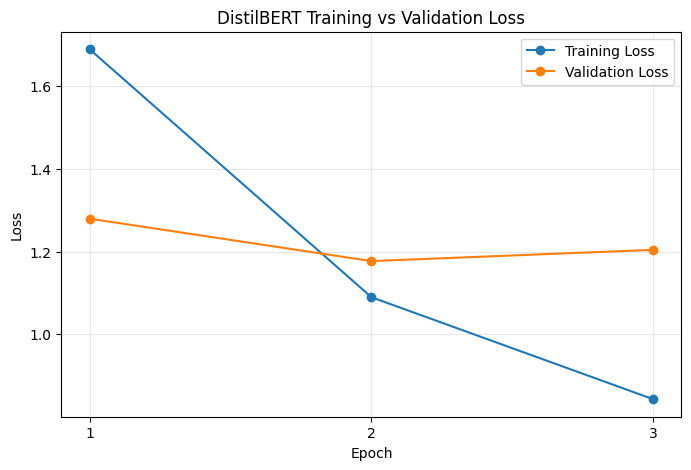

In [43]:
# Plot training and validation loss

history_df = pd.DataFrame(final_history.history)
history_df["epoch"] = np.arange(1, len(history_df) + 1)

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["loss"], marker="o", label="Training Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DistilBERT Training vs Validation Loss")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

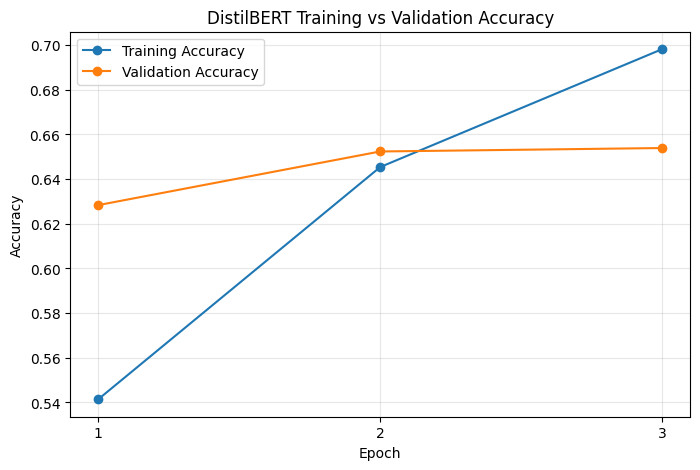

In [44]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DistilBERT Training vs Validation Accuracy")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### A.3.2 - Final Test Evaluation

After retraining, we evaluated the final DistilBERT model on the untouched test split. In addition to the built-in test loss and accuracy from Keras, we generated class predictions and computed **macro-F1** and **weighted-F1** to capture performance under class imbalance. We also produced a classification report and confusion matrix to support more detailed interpretation of class-level behavior.

In [45]:
# Evaluate the final model on the untouched test set

test_loss, test_accuracy = final_model.evaluate(X_test_text, y_test, verbose=0)

test_logits = final_model.predict(X_test_text, batch_size=FINAL_BATCH_SIZE, verbose=1)
y_test_pred = np.argmax(test_logits, axis=1)

test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, y_test_pred, average="weighted")

print("Final Test Metrics")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro-F1: {test_macro_f1:.4f}")
print(f"Test Weighted-F1: {test_weighted_f1:.4f}")

627/627 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step
Final Test Metrics
Test Loss: 1.1861
Test Accuracy: 0.6490
Test Macro-F1: 0.5812
Test Weighted-F1: 0.6591


In [46]:
# Clean summary table of final test metrics

a3_test_metrics = pd.DataFrame({
    "Metric": ["Test Loss", "Test Accuracy", "Test Macro-F1", "Test Weighted-F1"],
    "Value": [test_loss, test_accuracy, test_macro_f1, test_weighted_f1]
})

display(a3_test_metrics)

,Metric,Value
0,Test Loss,1.186062
1,Test Accuracy,0.649014
2,Test Macro-F1,0.581201
3,Test Weighted-F1,0.659062


The table above summarizes the overall test metrics. To better understand difficult categories, the next table highlights the lowest-performing classes by F1-score on the test set.

In [47]:
# Create per-class evaluation table

class_report_dict = classification_report(
    y_test,
    y_test_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

class_report_df = pd.DataFrame(class_report_dict).transpose()

per_class_df = class_report_df.loc[label_encoder.classes_].copy()
per_class_df = per_class_df.rename(columns={
    "precision": "Precision",
    "recall": "Recall",
    "f1-score": "F1-Score",
    "support": "Support"
})

per_class_df["Support"] = per_class_df["Support"].astype(int)

per_class_df = per_class_df.sort_values("F1-Score", ascending=False)

In [48]:
# Lowest-performing classes by F1-score

display(per_class_df.sort_values("F1-Score", ascending=True).head(15))

,Precision,Recall,F1-Score,Support
EDUCATION,0.248201,0.690000,0.365079,100
FIFTY,0.292969,0.535714,0.378788,140
WORLD NEWS,0.369748,0.405530,0.386813,217
WOMEN,0.342984,0.452941,0.390368,340
GOOD NEWS,0.392405,0.446043,0.417508,139
IMPACT,0.415094,0.445087,0.429568,346
TASTE,0.360129,0.535885,0.430769,209
LATINO VOICES,0.328767,0.637168,0.433735,113
CULTURE & ARTS,0.406015,0.524272,0.457627,103
PARENTS,0.473404,0.456410,0.464752,390


In [49]:
display(per_class_df.head(15))

,Precision,Recall,F1-Score,Support
STYLE & BEAUTY,0.869430,0.882229,0.875783,951
TRAVEL,0.852544,0.830131,0.841189,989
HOME & LIVING,0.841849,0.831731,0.836759,416
WEDDINGS,0.811518,0.849315,0.829987,365
DIVORCE,0.790191,0.847953,0.818054,342
SPORTS,0.769841,0.793456,0.781470,489
QUEER VOICES,0.809278,0.746434,0.776587,631
WELLNESS,0.794840,0.708754,0.749333,1782
FOOD & DRINK,0.747126,0.730337,0.738636,623
POLITICS,0.929695,0.577934,0.712778,3272


In [50]:
# Overall classification summary rows

overall_rows = class_report_df.loc[["macro avg", "weighted avg"]].copy()
display(overall_rows)

,precision,recall,f1-score,support
macro avg,0.552189,0.638025,0.581201,20035.0
weighted avg,0.695208,0.649014,0.659062,20035.0


The figure below shows the full confusion matrix on the test set. Because the dataset includes 41 classes, the full matrix is dense, so we also include a focused confusion view and the most common confusion pairs afterward to make the error patterns easier to interpret.

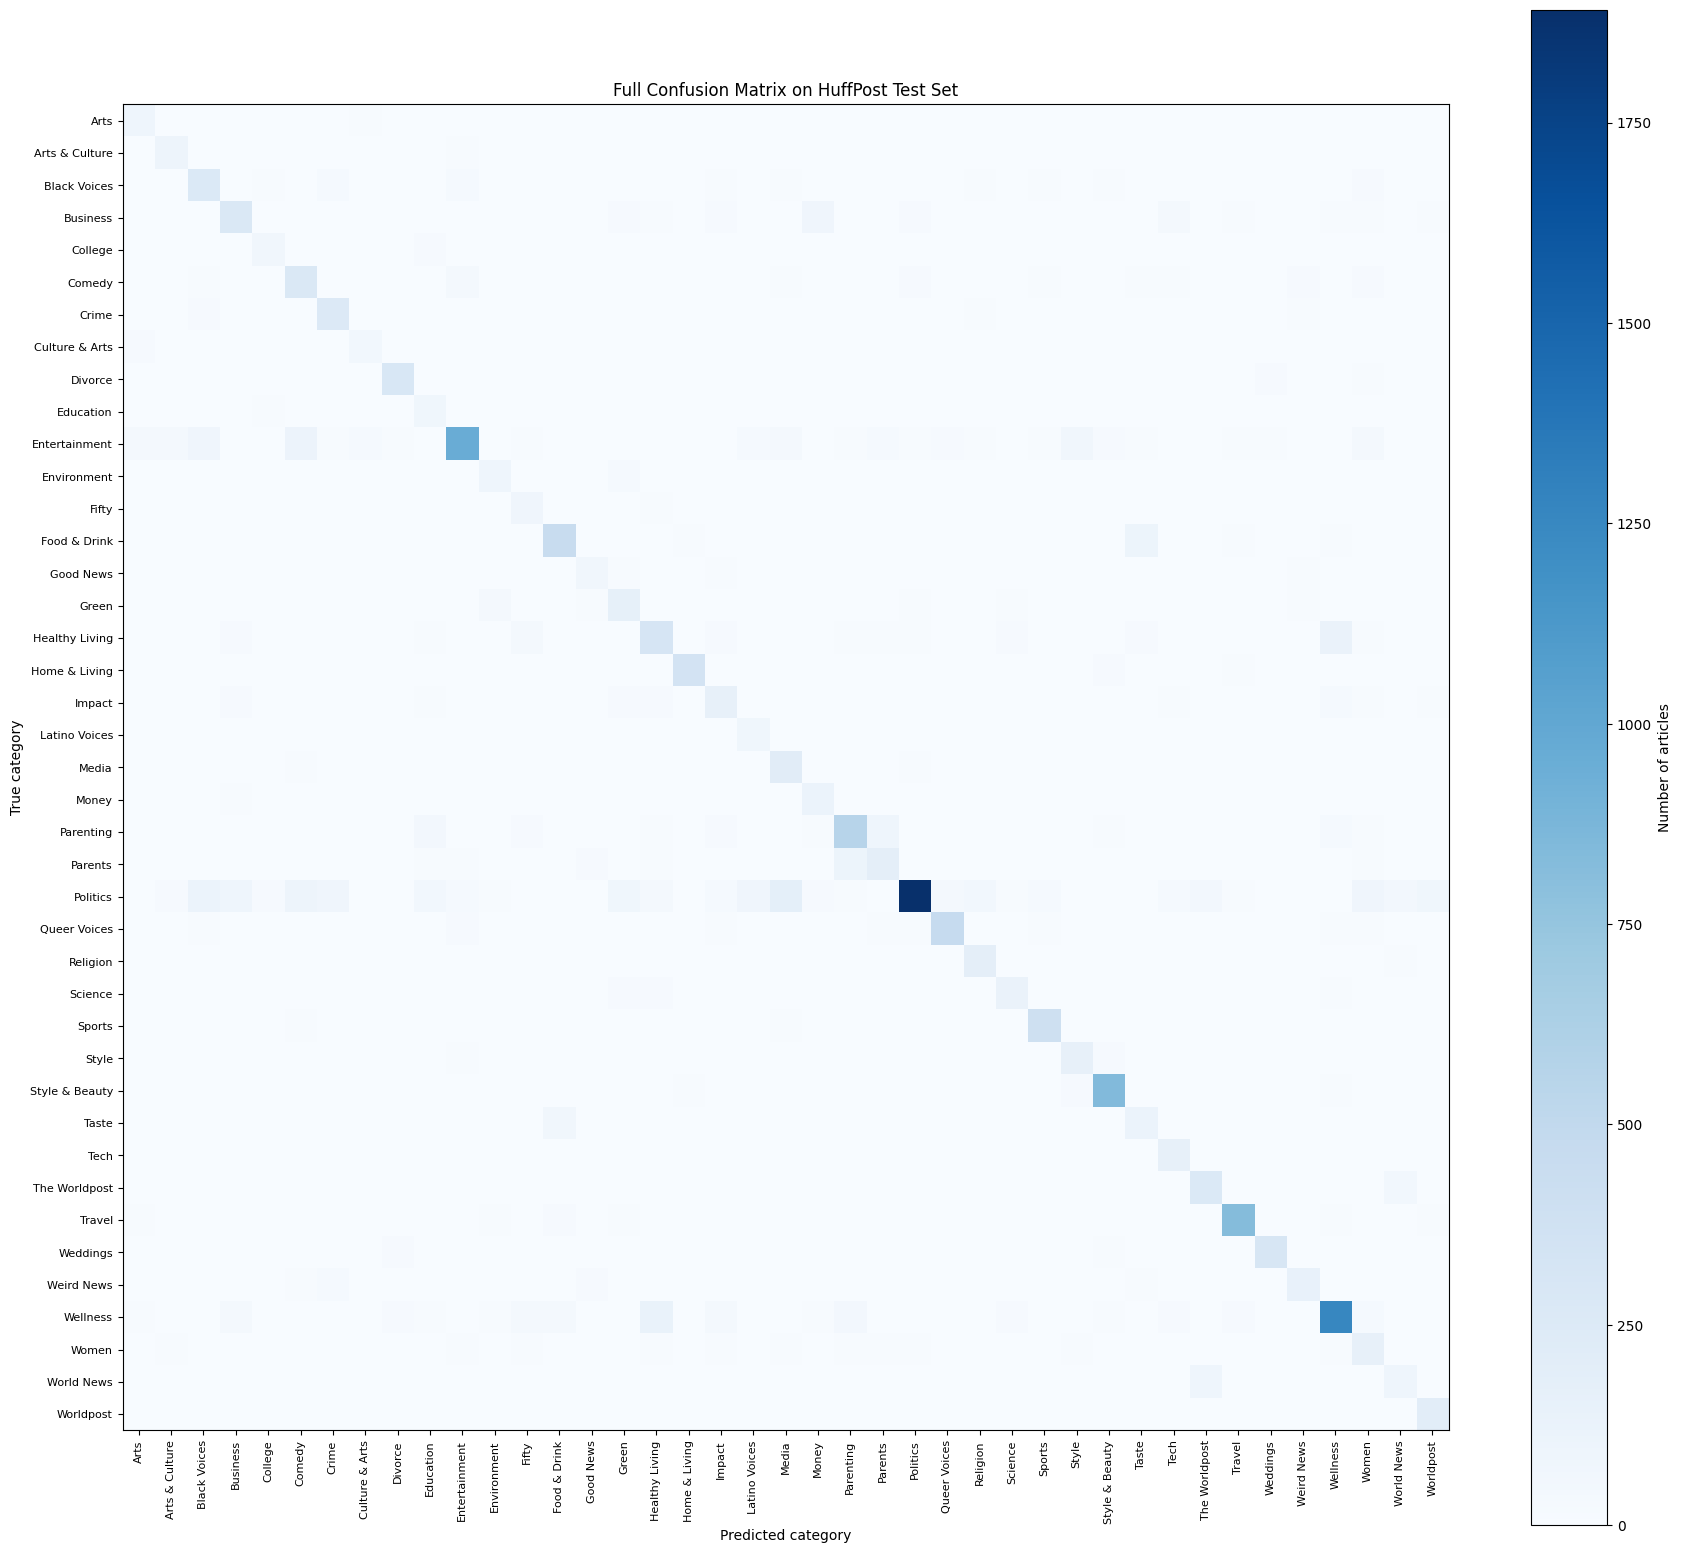

In [51]:
# Full confusion matrix with category labels

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# get class names from the label encoder
class_names = [name.title() for name in label_encoder.classes_]

# build confusion matrix
cm_full = confusion_matrix(y_test, y_test_pred)

# plot
plt.figure(figsize=(18, 16))
plt.imshow(cm_full, cmap="Blues")
plt.colorbar(label="Number of articles")

plt.title("Full Confusion Matrix on HuffPost Test Set")
plt.xlabel("Predicted category")
plt.ylabel("True category")

# show category names instead of numbers
plt.xticks(range(len(class_names)), class_names, rotation=90, fontsize=8)
plt.yticks(range(len(class_names)), class_names, fontsize=8)

plt.tight_layout()
plt.show()

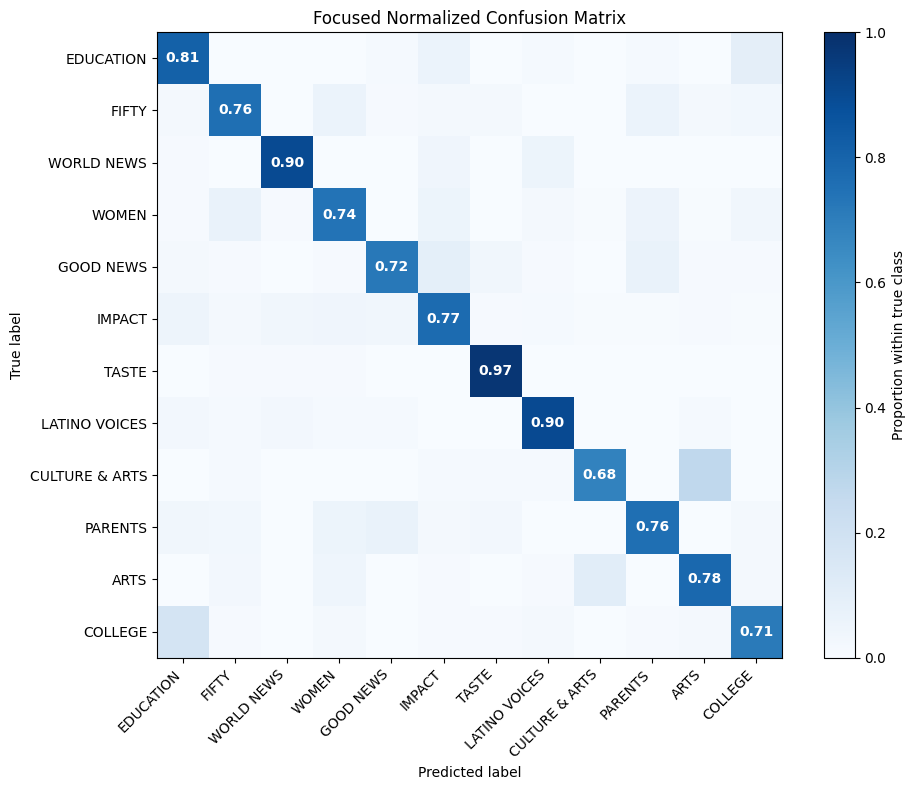

In [53]:
# Focused confusion matrix for lowest-performing classes


# choose the 12 lowest-performing classes
worst_classes = per_class_df.sort_values("F1-Score").head(12).index.tolist()

# full confusion matrix
class_names = list(label_encoder.classes_)
cm = confusion_matrix(y_test, y_test_pred)

# get the row/column positions for those classes
focus_idx = [class_names.index(c) for c in worst_classes]

# keep only those classes
cm_small = cm[np.ix_(focus_idx, focus_idx)]

# row normalize
cm_small = cm_small / cm_small.sum(axis=1, keepdims=True)

# plot
plt.figure(figsize=(10, 8))
plt.imshow(cm_small, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Proportion within true class")

plt.xticks(range(len(worst_classes)), worst_classes, rotation=45, ha="right")
plt.yticks(range(len(worst_classes)), worst_classes)

plt.title("Focused Normalized Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")

# show only diagonal values
for i in range(len(worst_classes)):
    plt.text(i, i, f"{cm_small[i, i]:.2f}",
             ha="center", va="center",
             color="white", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

### A.3.3 - Focused Confusion Analysis

Because the HuffPost dataset contains many classes, the full confusion matrix is useful for completeness but can be visually dense. To make interpretation easier, we also extract the most frequent off-diagonal errors. This helps identify which categories are most often confused with one another.

In [54]:
# Most common confusion pairs

cm_full = confusion_matrix(y_test, y_test_pred)

cm_offdiag = cm_full.copy()
np.fill_diagonal(cm_offdiag, 0)

confusions = []
for true_idx in range(cm_offdiag.shape[0]):
    for pred_idx in range(cm_offdiag.shape[1]):
        count = cm_offdiag[true_idx, pred_idx]
        if count > 0:
            confusions.append({
                "True Class": label_encoder.classes_[true_idx],
                "Predicted Class": label_encoder.classes_[pred_idx],
                "Count": int(count)
            })

confusions_df = (
    pd.DataFrame(confusions)
    .sort_values("Count", ascending=False)
    .reset_index(drop=True)
)

display(confusions_df.head(15))

,True Class,Predicted Class,Count
0,POLITICS,MEDIA,175
1,WELLNESS,HEALTHY LIVING,126
2,HEALTHY LIVING,WELLNESS,125
3,POLITICS,BLACK VOICES,117
4,ENTERTAINMENT,COMEDY,107
5,FOOD & DRINK,TASTE,102
6,PARENTS,PARENTING,98
7,POLITICS,COMEDY,91
8,WORLD NEWS,THE WORLDPOST,85
9,PARENTING,PARENTS,84


### A.3.4 - Summary of final model performance

The final DistilBERT model is evaluated using both overall and class-sensitive metrics. Accuracy provides a broad summary of performance, while macro-F1 and weighted-F1 give a more informative view under class imbalance. The per-class results, confusion matrix, and most common confusion pairs help show which categories remain difficult, especially where news topics overlap semantically.

Together, these results provide a fuller picture of model quality than any single summary metric alone and help support the final discussion in the report.

In [55]:
# Compact final evaluation printout for easy reference

print("=== Final DistilBERT Test Performance ===")
print(f"Accuracy     : {test_accuracy:.4f}")
print(f"Macro-F1     : {test_macro_f1:.4f}")
print(f"Weighted-F1  : {test_weighted_f1:.4f}")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Classes      : {num_classes}")
print(f"Test Samples : {len(y_test)}")

=== Final DistilBERT Test Performance ===
Accuracy     : 0.6490
Macro-F1     : 0.5812
Weighted-F1  : 0.6591
Test Loss    : 1.1861
Classes      : 41
Test Samples : 20035
